#IJC437 Week 4: Regression

In this session, you will be working with practical examples of regression. After loading data and cleaning/transforming it as you have learned last week, the next step is to analyse it for new insights or predictive modeling.

**Learning objectives**

At the end of today’s session, you should be able to:
1. Fit a linear regression model in Python, using single-variable or multi-variable data;
2. Compare the fit of two linear regression models and one multiple linear regression model
3. Evaluate linear regression models

## 1. Introduction

As we discussed on Monday, regression is the task of numeric prediction. The general idea is that we have a set of data points (samples), each of which have:
* **Independent variables**: Attributes that describe the data points, which we can
observe and want to use to predict the numeric outcome.
* **Dependent variable**: The numeric attribute of each data point that we want to predict. Note you are (usually) only working with one of these at a time.

With a linear model, as we are using today, we will be fitting a straight line to get as close to as many of the observed data points as possible. Starting with a single independent variable, the model is
represented as the line *y = ax + b*, which we can break down as:
* *y* is the dependent variable to predict
* *x* is the independent variable we have observed as input
* *a* and *b* are model parameters, which we will be estimating

Breaking down the model equation into its component elements is simple in this case, but will get much more complicated as you move into more complex models. Being able to analyse what the model equation and its components represent is a valuable skill to practice!

**Note**: Linear regression makes some assumptions; the main one being that the distribution of variables is basically normal (if not there are methods to deal with this, e.g. transform data into a normal distribution), see https://www.kdnuggets.com/2017/11/first-linear-regression-assumptions.html




### 1.1. Basic setup

Let's start by importing the libraries we will need in this activity.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
os.path.exists('/content/drive/MyDrive/Colab Notebooks')

True

In [10]:
os.chdir('/content/drive/MyDrive/Colab Notebooks')

In [12]:
ls


 20260423_annotation_report.ipynb
'20261002 of IntroPython_part1.ipynb'
'20261002 of IntroPython_part2.ipynb'
'Computer Vision Session.ipynb'
'Copy of 20260317_annotation_report.ipynb'
'Copy of Basics of AI: Supervised Machine Learning.ipynb'
'Copy of [Exercises w  Model Answers] IJC317-Lab-04-Deep_Learning_for_Image_Classification_20260304.ipynb'
'Copy of IJC201_Week-2.ipynb'
'Copy of IJC201_Week-3_withSolutions.ipynb'
'Copy of IJC201 Week 5 Lab.ipynb'
'Copy of IJC317-Lab-05-Deep_Learning_for_Image_Segmentation.ipynb'
'Copy of IJC317-Lab-08-Instruction_Following_and_Generative_Sentiment_Analysis.ipynb'
'Copy of IJC317 Lab week 1 (Working with an AI)'
'Copy of IJC317 Lab week 3 (Building and Evaluating Toxic Comment Detection Systems)'
'Copy of IJC317 Lab week 6 (Building and Evaluating Recommender Systems)'
'Copy of IJC317 Lab week 7 (Recommender System Challenges)'
'Copy of IJC437-Week4.ipynb'
'Copy of IJC446 - Intro to Python.ipynb'
'Copy of IJC446 - Python 2 Data Analysis.ipynb'
'C

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Prepare the dataset

We will be using the `hills` dataset. Please download the file [hills.csv](https://vincentarelbundock.github.io/Rdatasets/csv/DAAG/hills.csv) (also available from Blackboard) and upload it to your Google Colab session.

This dataset contains records times for hill climb races in Scotland. It has three variables:

* `dist`: The horizontal distance involved in the hill climb (in miles)
* `climb`: The vertical distance involved in the hill climb (in feet)
* `time`: The record time of the hill climb (in hours)

For more info on this dataset, see https://rdrr.io/cran/MASS/man/hills.html

### 2.1. Setting up training and testing data

We are working on predictive modelling today. That means we are going to use data that we have observed to fit a model. But then we want to see how well that model will do well in practice, i.e. how it will generalise to new data. As we discussed in the lecture, that means we need two separate splits of the dataset:
* The training set, which is the data samples we will use to fit the model (our "observed" data)
* And the test set, which is the data samples we will use to test the model. In effect, we are pretending we have never seen these samples before – because our model hasn't!

**Splitting your training and testing data is the VERY FIRST thing you should do
when working on predictive modelling**. If you start exploring your test data or visualising it with descriptive analyses, it can bias how you build your model so you are "teaching to the test" instead of estimating real generalisation.

So, let's load the dataset and check how many rows it has:

In [14]:
# Load hills.csv into a DataFrame
hills_dataset = pd.read_csv('hills.csv')

# To get the number of rows, you can use 'shape' which will return the (rows, columns)
rows, columns = hills_dataset.shape
print(f"The dataset has {rows} rows and {columns} columns.")

# Alternatively, you can use the 'len' function
print(len(hills_dataset))

The dataset has 35 rows and 4 columns.
35


There are 35 rows, so we are going to take the first 30 for training and the last 5 for testing.

In [15]:
# Get row 1-30 as our training dataset
hills_train = hills_dataset.head(30)

# Get row 31-35 as our test dataset
hills_test = hills_dataset.tail(5)


In [16]:
hills_train.head()

,rownames,dist,climb,time
0,Greenmantle,2.4,650,0.268056
1,Carnethy,6.0,2500,0.805833
2,Craig Dunain,6.0,900,0.560833
3,Ben Rha,7.5,800,0.760000
4,Ben Lomond,8.0,3070,1.037778


In [17]:
hills_test.head()

,rownames,dist,climb,time
30,Ben Nevis,10.0,4400,1.426389
31,Knockfarrel,6.0,600,0.539722
32,Two Breweries,18.0,5200,2.837500
33,Cockleroi,4.5,850,0.468333
34,Moffat Chase,20.0,5000,2.663889


### 2.2. Exploring the dataset

Now we can start exploring the dataset. Let's first get a sense of what the rows look like by sampling the first 10 rows.



In [18]:
print(hills_train.head(10))

       rownames  dist  climb      time
0   Greenmantle   2.4    650  0.268056
1      Carnethy   6.0   2500  0.805833
2  Craig Dunain   6.0    900  0.560833
3       Ben Rha   7.5    800  0.760000
4    Ben Lomond   8.0   3070  1.037778
5      Goatfell   8.0   2866  1.220278
6  Bens of Jura  16.0   7500  3.410278
7   Cairnpapple   6.0    800  0.606111
8        Scolty   5.0    800  0.495833
9      Traprain   6.0    650  0.662500


And we can use `describe()` to get basic statistics on the dataset variables.

In [19]:
print(hills_train.describe())

            dist        climb       time
count  30.000000    30.000000  30.000000
mean    6.830000  1582.866667   0.860843
std     5.055018  1399.844197   0.749507
min     2.000000   300.000000   0.265833
25%     4.500000   687.500000   0.452917
50%     6.000000   975.000000   0.634306
75%     7.250000  2175.000000   0.988750
max    28.000000  7500.000000   3.410278


Now, remember that the dependent variable we are trying to predict is `time`: that is, we are interested in how `time` changes as a function of `dist` or `climb`. The first step is a *sanity* check to look visually at the relationship between each of the independent variables and `time`.

Let's create a scatterplot comparing `dist` and `time`:

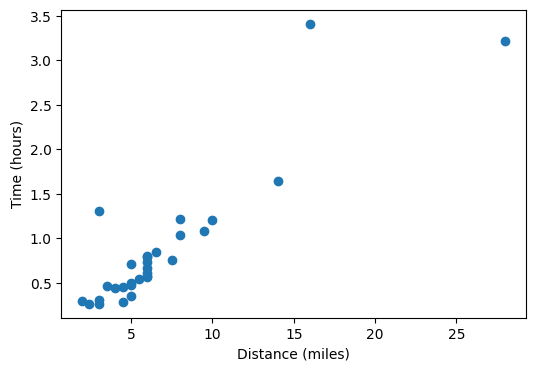

In [20]:
# Scatterplot: Distance (dist) vs. Time (time)
plt.figure(figsize=(6, 4))
plt.scatter(data=hills_train, x="dist", y="time")
plt.xlabel("Distance (miles)")
plt.ylabel("Time (hours)")
plt.show()

We can see that there is a linear relationship between `distance` and `time`, so a linear regression model may work well here.


---
&#9998; **Exercise:** Your task now is to create a scatterplot comparing the other independent variable: `climb` and `time`.

---





In [ ]:
# Exercise 2.2: scatterplot of climb vs time
# Create a new figure, 6 inches wide and 4 inches tall
plt.figure(figsize=(6, 4))
# Plot each hill as a point: climb on the x-axis, time on the y-axis, using training data only
plt.scatter(data=hills_train, x="climb", y="time")
# Label the x-axis with the variable and its unit
plt.xlabel("Climb (feet)")
# Label the y-axis with the variable and its unit
plt.ylabel("Time (hours)")
# Draw the figure
plt.show()

There appears to be much more variation in the relationship between `climb` and `time` than between `dist` and `time`. To check this numerically, we can calculate the Pearson correlation scores between the two pairs of variables.

You can do this using `scipy.stats.pearsonr(x, y)` function.
For ore information about this function, see: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html

In [ ]:
# First, we need to import the library
import scipy.stats

# Calculate Pearson correlation between distance and time
correlation, p_value = scipy.stats.pearsonr(hills_train["dist"], hills_train["time"])
print(f"Pearson correlation (dist vs time): {correlation}")
print(f"p-value: {p_value}")

# Calculate Pearson correlation between climb and time
correlation, p_value = scipy.stats.pearsonr(hills_train["climb"], hills_train["time"])
print(f"Pearson correlation (climb vs time): {correlation}")
print(f"p-value: {p_value}")

This confirms what we saw in the graphs: both `climb` and `dist` are positively correlated with `time`. However, `dist` has a stronger correlation (Pearson's r=0.89) compared to `climb` (Pearson's r=0.73).

**This suggests that if you are using `climb` alone, you are likely to capture *less* of what actually informs the outcome (`time`) than if you used `dist`.**

### 2.3. Fitting the first linear regression

Based on our results above, let's try to fit our first linear regression model using `dist` to predict `time`. We are going to call our model: `model_dist`.



In [ ]:
from sklearn.linear_model import LinearRegression

# Prepare training data (independent variable X and dependent variable y)
X_train = hills_train[["dist"]]
y_train = hills_train["time"]

# Initialise and fit the Linear Regression model
model_dist = LinearRegression()
model_dist.fit(X_train, y_train)

# Summary of the model

print('Model intercept: ', model_dist.intercept_)
print('Model coefficients: ', model_dist.coef_)

The model coefficient shows the average increase in `time` for every one-unit increase in `dist` (negative would signal a decrease). So the equation the model has produced is: $time = -0.04 + (0.13 * dist)$.

Let's calculate the $R^2$ (R-squared) score to see how much of the variation in the dependent variable is explained by the regression model.

In [ ]:
# Calculate R-squared directly from the model
r_squared_dist = model_dist.score(X_train, y_train)
print('R-squared: ', {r_squared_dist})

In this case, our model is performing fairly well, as it is able to explain about 79.3% of the variance in race times using only the distance.

---
&#9998; **Exercise**: Fit a new linear regression model (name it **model_climb**) on the `hills` training dataset, using `climb` instead of `dist` as the independent variable. Compare the $R^2$ score: which independent variable is a better predictor of `time`? Does that make sense with what you saw in the scatterplots earlier?

---

In [ ]:
# Exercise 2.3: fit model_climb and compare R-squared with model_dist
# Select climb as the predictor; double brackets keep it a 2D table, as sklearn requires
X_train_climb = hills_train[["climb"]]
# Select time as the target (the value we want to predict)
y_train = hills_train["time"]

# Create an empty linear regression model
model_climb = LinearRegression()
# Estimate the intercept and slope from the training data
model_climb.fit(X_train_climb, y_train)

# Show the fitted intercept (predicted time when climb = 0)
print('Model intercept: ', model_climb.intercept_)
# Show the fitted slope (extra hours per extra foot of climb)
print('Model coefficients: ', model_climb.coef_)

# R-squared on the training data: share of variance in time explained by climb
r_squared_climb = model_climb.score(X_train_climb, y_train)
# Print the climb model's R-squared
print('R-squared (climb): ', r_squared_climb)
# Print the dist model's R-squared (computed earlier) for side-by-side comparison
print('R-squared (dist):  ', r_squared_dist)
# Expected: dist explains more variance than climb, consistent with
# the stronger Pearson r for dist (0.89) than climb (0.73).

### 2.4. Inspecting the linear regression models

Let's inpect our first linear regression model (`model_dist`) by drawing the regression line on the graph of the data points.

In [ ]:
X_train = hills_train[["dist"]]
y_train = hills_train["time"]

def myfunc(x):
  return model_dist.intercept_ + model_dist.coef_ * x

plt.scatter(X_train, y_train)
plt.plot(X_train, myfunc(X_train), color='red')
plt.xlabel("Distance (miles)")
plt.ylabel("Time (hours)")
plt.show()

This gives you an overall sense of how well the model fits the data: here we see it follows the trend line but leaves some variance that is not accounted for.

To see the remaining variance in more detail, we can graph the **residuals** of the model. Remember that these are the difference between the *predicted* value for a sample (based on the independent variables) and the *actual* value (of the dependent variable).

In [ ]:
# Let's make a copy of the dataset so we can leave the original untouched
hills_dist_residuals = hills_train.copy()

# Use double brackets [['dist']] to ensure a 2D DataFrame is passed to predict()
hills_dist_residuals['predicted_time'] = model_dist.predict(hills_dist_residuals[['dist']])
hills_dist_residuals['residuals'] = hills_dist_residuals['time'] - hills_dist_residuals['predicted_time']

hills_dist_residuals.head(10)

You can see that Bens of Jura has a much larger residual than most of the other points. in this case, our model significantly underestimated the time by over 1.33 hours. This suggests it may be an *outlier*, a point that does not follow the same distribution as the other samples.

To investigate this further, let's plot a graph to visualise the predicted value for each point against its calculated residual. A good residual plot should have points randomly scattered around the horizontal line at $y = 0$, indicating that the errors are independent and have constant variance. Since the table above shows that most of the residuals are less than 0.5, we will also annotate intances whose residuals are above 0.5.

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(hills_dist_residuals['predicted_time'], hills_dist_residuals['residuals'])
plt.axhline(0, color="red", linestyle="--")

# Annotate prominent outliers whose absolute residuals are above 0.5
outliers = hills_dist_residuals.loc[hills_dist_residuals["residuals"].abs() > 0.5]
for idx, row in outliers.iterrows():
    plt.annotate(row['rownames'], (row["predicted_time"], row["residuals"]), textcoords="offset points", xytext=(5, 5))

plt.xlabel("Fitted values (Predicted Time) by model_dist")
plt.ylabel("Residuals (Actual-Predicted)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Now we can see very clearly that Bens of Jura and Knock Hill are very much outliers in these data.





---


&#9998; **Exercise**: Graph the linear model you trained using `climb` as the predictor earlier, along with its residuals. How does the fit of the model compare to using `dist` as the predictor? Does this align with what you saw earlier in the analysis when comparing the two? Are the same points outliers for the `climb` model, or are there different outliers?



---



In [ ]:
# Exercise 2.4: regression line and residuals for model_climb
# Select climb as the predictor (2D table for sklearn)
X_train_climb = hills_train[["climb"]]
# Select time as the target
y_train = hills_train["time"]

# Get the row order that sorts hills by climb, so the line is drawn left to right
order = X_train_climb["climb"].argsort()
# Reorder the predictor rows using that order
x_sorted = X_train_climb.iloc[order]
# Plot the actual data points
plt.scatter(X_train_climb, y_train)
# Draw the model's predicted values as a red line
plt.plot(x_sorted, model_climb.predict(x_sorted), color='red')
# Label the x-axis
plt.xlabel("Climb (feet)")
# Label the y-axis
plt.ylabel("Time (hours)")
# Draw the figure
plt.show()

# Copy the training data so the original stays untouched
hills_climb_residuals = hills_train.copy()
# Add the model's predicted time for each hill
hills_climb_residuals['predicted_time'] = model_climb.predict(hills_climb_residuals[['climb']])
# Residual = actual minus predicted (positive means the model underestimated)
hills_climb_residuals['residuals'] = hills_climb_residuals['time'] - hills_climb_residuals['predicted_time']
# Show the first 10 rows with predictions and residuals
display(hills_climb_residuals.head(10))

# Create a new figure for the residual plot
plt.figure(figsize=(7, 5))
# Plot residuals (y) against fitted values (x)
plt.scatter(hills_climb_residuals['predicted_time'], hills_climb_residuals['residuals'])
# Draw a dashed reference line at residual = 0 (perfect prediction)
plt.axhline(0, color="red", linestyle="--")

# Pick out hills whose absolute residual is above 0.5
outliers_climb = hills_climb_residuals.loc[hills_climb_residuals["residuals"].abs() > 0.5]
# Loop over each outlier hill
for idx, row in outliers_climb.iterrows():
    # Write the hill's name next to its point, offset slightly so it is readable
    plt.annotate(row['rownames'], (row["predicted_time"], row["residuals"]),
                 textcoords="offset points", xytext=(5, 5))

# Label the x-axis
plt.xlabel("Fitted values (Predicted Time) by model_climb")
# Label the y-axis
plt.ylabel("Residuals (Actual-Predicted)")
# Add a light dashed grid to help read values
plt.grid(True, linestyle="--", alpha=0.5)
# Draw the figure
plt.show()

# Print the names of the outlier hills to compare with the dist model
print("Outliers (|residual| > 0.5):", list(outliers_climb['rownames']))
# Print the single largest absolute residual
print("Largest absolute residual:", hills_climb_residuals['residuals'].abs().max())

### 2.5. Making predictions with the linear regression model

Now that we have fitted our models, we want to use them to predict the time for climbing new hills (i.e., hills we did not observe when fitting the model). To do so, we will use the `predict()` function on the new, unseen data. Let's start by using our first model (`model_dist`), which used just the distance for predicting the time:

In [ ]:
# Prepare training data (independent variable X and dependent variable y)
X_test = hills_test[["dist"]]
y_test = hills_test["time"]

# Predict using the trained model
y_test_pred = model_dist.predict(X_test)

print(y_test_pred)

Now, given that we actually know what the *true* values are for these points, we can see how well our model is **actually** doing on these new samples by calculating the residuals ourselves.



In [ ]:
hills_dist_test_residuals = hills_test.copy()
hills_dist_test_residuals['predicted_time'] = model_dist.predict(hills_dist_test_residuals[['dist']])
hills_dist_test_residuals['residuals'] = hills_dist_test_residuals['time'] - hills_dist_test_residuals['predicted_time']

hills_dist_test_residuals

This also allows us to calculate different evaluation metrics, such as: **mean absolute errors (MAE)** and **sum of squared errors (SSE)**.

Alternatively you can use available libraries from `sklearn.metrics` to calculate **mean_squared_errors (MSE)** and **root_mean_squared_errors (RMSE)**.

In [ ]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error
import numpy as np

mae_dist = np.mean(abs(hills_dist_test_residuals['residuals']))
sse_dist = (hills_dist_test_residuals['residuals']**2).sum()
mse_dist = mean_squared_error(hills_dist_test_residuals['time'], hills_dist_test_residuals['predicted_time'])
rmse_dist = root_mean_squared_error(hills_dist_test_residuals['time'], hills_dist_test_residuals['predicted_time'])

print("MAE = ", mae_dist)
print("SSE = ", sse_dist)
print("MSE = ", mse_dist)
print("RMSE = ", rmse_dist)


All the above errors measure the average size of prediction errors. Lower error scores mean your models have better accuracy than higher error scores.

The results above indicate that our model is able to use distance to predict the time with a mean absolute error (MAE) of 0.20. This indicates that our model's prediction is off by 0.20 hours (12 minutes) on average. Given that the race times range between 0.26 hours (15 minutes) to 3.4 hours (3 hours 24 minutes), this represents a relatively small error margin.

MAE will treat all errors equally. If you would like to use a metric that gives a higher penalty to large outliers, it is best to report MSE/RMSE.

---

&#9998; **Exercise**: Use the `model_climb` that you fit earlier to
make predictions on the `hills` test data. How do these predictions compare to the predictions using `dist`? Are the errors in the two models different? How do the error values compare between the two models, and what does that tell you about their fit?

---

In [ ]:
# Exercise 2.5: evaluate model_climb on the test set
# Select climb from the five unseen test hills
X_test_climb = hills_test[["climb"]]

# Copy the test data so the original stays untouched
hills_climb_test_residuals = hills_test.copy()
# Predict time for each test hill using the climb model
hills_climb_test_residuals['predicted_time'] = model_climb.predict(X_test_climb)
# Residual = actual minus predicted
hills_climb_test_residuals['residuals'] = (hills_climb_test_residuals['time']
                                           - hills_climb_test_residuals['predicted_time'])
# Show actual, predicted and residual for each test hill
display(hills_climb_test_residuals)

# MAE: average size of the errors, all errors weighted equally
mae_climb = np.mean(abs(hills_climb_test_residuals['residuals']))
# SSE: sum of squared errors, penalises large errors more
sse_climb = (hills_climb_test_residuals['residuals']**2).sum()
# MSE: average squared error
mse_climb = mean_squared_error(hills_climb_test_residuals['time'], hills_climb_test_residuals['predicted_time'])
# RMSE: square root of MSE, back in hours
rmse_climb = root_mean_squared_error(hills_climb_test_residuals['time'], hills_climb_test_residuals['predicted_time'])

# Build a table with the dist model's errors (from earlier) and the climb model's errors
comparison = pd.DataFrame({
    "model_dist":  [mae_dist, sse_dist, mse_dist, rmse_dist],
    "model_climb": [mae_climb, sse_climb, mse_climb, rmse_climb],
}, index=["MAE", "SSE", "MSE", "RMSE"])
# Show the comparison table
display(comparison)
# Lower error = better fit. Expect model_dist to have the smaller errors.

## 3. Multi-variate linear regression

So far we have only been using one independent variable at a time, but `hills` has two available: both `climb` and `dist` can reasonably be expected to affect the time required to climb a hill.

In these situations, we use *multivariate* regression (aka *multiple linear regression*), a regression with two or more predictor variables. Instead of modelling the dependent variable as a straight line, it is now modelled as a function of several different independent variables. However, it is still a linear combination of these values, i.e., $y = a + b_1x_1 + b_2x_2 + ...$

**Adding more independent variables cannot harm your model (at least on the training data), but it won't necessarily help it.** If a variable doesn't contribute anything to predicting the target value, it will just get ignored in regression.

### 3.1. Checking for collinearity

The important concept here is **collinearity**: when two variables change in line with each other. For example, if all the hills have the same slope and the `climb` changes in line with the `dist`, then combining the two variables won't tell me any more than using one on its own.

So first off, let's plot `dist` and `climb` together to see if they look collinear.

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(hills_train['dist'], hills_train['climb'])
plt.xlabel("Distance (miles)")
plt.ylabel("Climb (feet)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

There is some relationship, but also a lot of scatter - that's good! That means that adding them together *can* be helpful. Let's run a quick correlation test to make sure.

In [ ]:
# Calculate Pearson correlation between distance and climb
correlation, p_value = scipy.stats.pearsonr(hills_train["dist"], hills_train["climb"])
print(f"Pearson correlation (dist vs climb): {correlation}")
print(f"p-value: {p_value}")

A correlation of 0.523 shows that they are definitely correlated, but they are also definitely not perfect predictors of each other.

### 3.2. Fitting the multiple linear regression model

Let's train our multiple linear regression model using both `dist` and `climb` as our independent variables.

In [ ]:
# Prepare multiple features
features = ["dist", "climb"]

X_train_multi = hills_train[features]
y_train_multi = hills_train["time"]

# Initialise and fit the Multiple Linear Regression model
multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

# Summary of the model
print('Model intercept: ', multi_model.intercept_)
print('Model coefficients: ', multi_model.coef_)

# Calculate R-squared directly from the model
r_squared_multi = multi_model.score(X_train_multi, y_train_multi)

# For multiple variables, you will also need to report the adjusted R-squared formula:
n = len(hills_train)            # 30 rows
noOfPredictors = len(features)  # 2 features

adjusted_r_squared_multi = 1 - ((1 - r_squared_multi) * (n - 1)) / (n - noOfPredictors - 1)

print('R-squared: ', {r_squared_multi})
print('Adjusted R-squared: ', {adjusted_r_squared_multi})

Based on the intercept and coefficients, our model uses the following formula: $time = -0.16 + (0.1035*dist) + (0.0002*climb)$.

The model seems to work quite well as it shows that the independent variables are able to explain 88% of the variance in the dependent variable ($R^2$ = 0.89, Adjusted $R^2$ = 0.88).

### 3.3. Inspecting the model

Similar to our linear regression model, let's inspect how well our multiple linear regression model works by plotting the predicted time and the actual time.

In [ ]:
# Let's make a copy of the dataset so we can leave the original untouched
hills_multi_residuals = hills_train.copy()

hills_multi_residuals['predicted_time'] = multi_model.predict(hills_multi_residuals[features])
hills_multi_residuals['residuals'] = hills_multi_residuals['time'] - hills_multi_residuals['predicted_time']

hills_multi_residuals.head(10)

The residuals look smaller than our previous linear regression models. To inspect this further, let's create a scatter plot showing the predicted time and the residuals.

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(hills_multi_residuals['predicted_time'], hills_multi_residuals['residuals'])
plt.axhline(0, color="red", linestyle="--")

# Annotate prominent outliers whose absolute residuals are above 0.5
outliers = hills_multi_residuals.loc[hills_multi_residuals["residuals"].abs() > 0.5]
for idx, row in outliers.iterrows():
    plt.annotate(row['rownames'], (row["predicted_time"], row["residuals"]), textcoords="offset points", xytext=(5, 5))

plt.xlabel("Fitted values (Predicted Time)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Fitted with Outlier Labels")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Our scatter plot shows that this model performs better, as most of the residuals are below 0.5. However, let's inspect this further by plotting the actual time and the predicted time. In this graph, we will also create a line $y=x$ which captures cases where the predicted time is the same as the actual time (the ideal case!).


In [ ]:
# Create the actual vs. predicted plot for the test dataset
plt.figure(figsize=(7, 5))
plt.scatter(hills_multi_residuals['time'], hills_multi_residuals['predicted_time'], label="Predicted time")

plt.axline((0,0), slope=1, color='red', linestyle="--", linewidth=1.5, label = "Perfect prediction (y=x)")

plt.xlabel("Actual time (hours)")
plt.ylabel("Predicted time (hours)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

### 3.4. Making predictions using the test dataset
Let's try to use this model to make predictions using the test dataset.



In [ ]:
# Prepare our features for the test data
X_test_multi = hills_test[features]

# Specify the target variable in the test data
y_test_multi = hills_test["time"]

y_test_multi_pred = multi_model.predict(X_test_multi)

hills_test_multi_residuals = hills_test.copy()
hills_test_multi_residuals['predicted_time'] = multi_model.predict(hills_test_multi_residuals[features])
hills_test_multi_residuals['residuals'] = hills_test_multi_residuals['time'] - hills_test_multi_residuals['predicted_time']

hills_test_multi_residuals


We can now report the error metrics for this model:

In [ ]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error

mae_multi = np.mean(abs(hills_test_multi_residuals['residuals']))
sse_multi = (hills_test_multi_residuals['residuals']**2).sum()
mse_multi = mean_squared_error(hills_test_multi_residuals['time'], hills_test_multi_residuals['predicted_time'])
rmse_multi = root_mean_squared_error(hills_test_multi_residuals['time'], hills_test_multi_residuals['predicted_time'])

print("MAE = ", mae_multi)
print("SSE = ", sse_multi)
print("MSE = ", mse_multi)
print("RMSE = ", rmse_multi)

In [ ]:
# Create the actual vs. predicted plot for the test dataset
plt.figure(figsize=(7, 5))
plt.scatter(hills_test_multi_residuals['time'], hills_test_multi_residuals['predicted_time'], label="Predicted Time")

# Plot a diagonal reference line (y = x)
plt.axline((0,0), slope=1, color='red', linestyle="--", linewidth=1.5, label="Perfect Prediction (y=x)")

plt.xlabel("Actual time (hours)")
plt.ylabel("Predicted time (hours)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

# 4. Further Exercise: Linear Regression

Now that you have completed the exercise using a very small dataset, try developing a linear regression model using a bigger dataset. This will provide you with more opportunities to explore the use of different variables.

In this section, w[link text](https://)e will be using to use the [California Housing dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset), which comes built-in with `sklearn`. This is a convenient dataset for linear modelling, containing variables such as:
* `MedInc`: median income in block group
* `HouseAge`: median house age in block group
* `AveRooms`: average number of rooms per household
* `AveBedrms`: average number of bedrooms per household
* `Population`: block group population
* `AveOccup`: average number of household members
* `Latitude`: block group latitude
* `Longitude` block group longitude

We are going to use Regression to predict the target variable:
* `MedHouseVal`: the median house value as expressed in hundreds of thousands of dollars

For the purpose of this practical, we will only use the first 1000 rows.

**Note**: Notice that this dataset contains information for a block group (and not a house). Please read: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset for more information about dataset and make sure you understand what the dataset contains.


In [ ]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load California Housing dataset from scikit-learn
housing_raw = fetch_california_housing(as_frame=True)

# Extract into a standard pandas DataFrame
housing = housing_raw.frame

# Get the first 1000 rows
housing = housing.head(1000)



## 4.1. Setting up training and test data

Let's split our dataset into 70:30 training and test data. Because we only use the first 1000 rows, we can select the first 700 as our training data, and 300 rows as the test data.

In [ ]:
housing_train = housing.head(700)
housing_test = housing.tail(300)

print(housing_train.shape)
print(housing_test.shape)

## 4.2. Exploring the dataset

Now we can start exploring the training dataset. Let's first get a sense of what the dataset contains. You can do this by creating histogram to see the distribution of each variable, as you learnt last week.


In [ ]:
print(housing_train.describe())

# To get the number of rows, you can use shape (rows, columns) or len()
print("Shape of DataFrame:", housing.shape)
print("Number of rows:", len(housing))

Now, remember that the dependent variable we are trying to predict is `MedHouseVal`: that is, we are interested in how median house value in a block changes as a function of average number of rooms (`AveRooms`) or median income (`MedInc`). The first step is a sanity check to look visually at the relationship between each of the independent variables and the dependent variable.



In [ ]:
# Scatterplot: AveRooms vs. MedHouseVal
plt.figure(figsize=(6, 4))
plt.scatter(data=housing_train, x="AveRooms", y="MedHouseVal")
plt.title("Average Number of Rooms vs House Value")
plt.show()

In [ ]:
# Scatterplot: AveBedrms vs. MedHouseVal
plt.figure(figsize=(6, 4))
plt.scatter(data=housing_train, x="MedInc", y="MedHouseVal")
plt.title("Median Income vs House Value")
plt.show()

There appears to be much more variation in the relationship between `AveRooms` and `MedHouseVal` than between `MedInc` and `MedHouseVal`. To check this numerically, let's run a quick correlation analysis (calculates the Pearson Correlation and the p-value):

In [ ]:

# Ensure housing_train is a pandas DataFrame
housing_train = pd.DataFrame(housing_train)

# Calculate Pearson correlation
correlation, p_value = scipy.stats.pearsonr(housing_train["AveRooms"], housing_train["MedHouseVal"])
print(f"Pearson correlation: {correlation}")
print(f"p-value: {p_value}")

In [ ]:
# Calculate Pearson correlation
correlation, p_value = scipy.stats.pearsonr(housing_train["MedInc"], housing_train["MedHouseVal"])
print(f"Pearson correlation: {correlation}")
print(f"p-value: {p_value}")

This confirms what we saw in the graphs: both `AveRooms` and `MedInc` are positively correlated with `MedHouseVal`, but `MedInc` has a stronger correlation (Pearson's correlation=0.768 vs 0.55 for `AveRooms`). **This suggests that if you are using `AveRooms` alone, you are likely to capture less of what actually informs the outcome (`MedHouseVal`) than if you used `MedInc`.**

## 4.3. Fitting the linear regression model



In [ ]:
from sklearn.linear_model import LinearRegression

# Prepare training data (independent variable X and dependent variable y)
X_train = housing_train[["AveRooms"]]
y_train = housing_train["MedHouseVal"]

# Initialize and fit the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# summary of the model
print('Model intercept :', model.intercept_)
print('Model coefficients : ', model.coef_)

# Calculate performance
print(f"R-squared score: {model.score(X_train, y_train)}")


### 4.4. Evaluating on test data

Now we will evaluate our trained model on the unseen test dataset (`housing_test`) using the Mean Squared Error (MSE) metric.

In [ ]:
from sklearn.metrics import mean_squared_error

# Prepare test features and target
X_test = housing_test[["AveRooms"]]
y_test = housing_test["MedHouseVal"]

# Predict using the trained model
y_test_pred = model.predict(X_test)

# Calculate Mean Squared Error
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Test Mean Squared Error (MSE): {test_mse:.4f}")

### 4.5. Visualising Actual vs. Predicted Values on the Test Set
To see how well our predictions line up with the true values, we can plot the actual target values against our model's predictions. In a perfect model, all points would lie on the diagonal line ($y = x$).



In [ ]:


# Create the actual vs. predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(x=y_test, y=y_test_pred, color="purple", alpha=0.8, label="Predictions")

# Determine the range for the reference line
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

# Plot a diagonal reference line (y = x)
plt.axline((0,0), slope=1, color="red", linestyle="--", linewidth=1.5, label="Perfect Prediction (y=x)")

plt.title("Actual vs. Predicted MedHouseVal (Test Set)")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

---

&#9998; **Exercise:** Your task is to try to create a linear regression model using the `MedIncome` as the independent variable. How do the results compare to your first model?

---

In [ ]:
# Exercise 4: MedInc as the single predictor (train on housing_train, evaluate on housing_test)
# Training predictor: MedInc as a 2D table
X_train_inc = housing_train[["MedInc"]]
# Training target: median house value
y_train_inc = housing_train["MedHouseVal"]
# Test predictor: MedInc for the 300 held-out rows
X_test_inc = housing_test[["MedInc"]]
# Test target: the true house values we will compare against
y_test_inc = housing_test["MedHouseVal"]

# Create an empty linear regression model
model_inc = LinearRegression()
# Fit it on the training data only
model_inc.fit(X_train_inc, y_train_inc)

# Show the fitted intercept
print('Intercept:', model_inc.intercept_)
# Show the fitted slope (change in house value per unit of median income)
print('Coefficient:', model_inc.coef_)

# Predict house values for the test rows
y_pred_inc = model_inc.predict(X_test_inc)
# R-squared on the training data
print(f"Train R-squared: {model_inc.score(X_train_inc, y_train_inc):.4f}")
# R-squared on the test data (how well it generalises)
print(f"Test R-squared:  {model_inc.score(X_test_inc, y_test_inc):.4f}")
# Mean squared error on the test data
test_mse_inc = mean_squared_error(y_test_inc, y_pred_inc)
# Print the MedInc model's test MSE
print(f"Test MSE (MedInc):   {test_mse_inc:.4f}")

# Refit the AveRooms model under its own name so the earlier `model` is not relied on
m_rooms = LinearRegression().fit(housing_train[["AveRooms"]], housing_train["MedHouseVal"])
# Predict test house values from AveRooms
rooms_pred = m_rooms.predict(housing_test[["AveRooms"]])
# Test R-squared for the AveRooms model
print(f"Test R-squared (AveRooms): {m_rooms.score(housing_test[['AveRooms']], y_test_inc):.4f}")
# Test MSE for the AveRooms model, to compare with MedInc
print(f"Test MSE (AveRooms): {mean_squared_error(y_test_inc, rooms_pred):.4f}")

# Create a new figure
plt.figure(figsize=(7, 5))
# Plot actual (x) against predicted (y) house values on the test set
plt.scatter(x=y_test_inc, y=y_pred_inc, color="purple", alpha=0.8, label="Predictions")
# Draw the y = x line; points on it are perfect predictions
plt.axline((0,0), slope=1, color="red", linestyle="--", linewidth=1.5, label="Perfect Prediction (y=x)")
# Add a title
plt.title("Actual vs. Predicted MedHouseVal (MedInc model, Test Set)")
# Label the x-axis
plt.xlabel("Actual MedHouseVal")
# Label the y-axis
plt.ylabel("Predicted MedHouseVal")
# Show the legend
plt.legend()
# Add a light dashed grid
plt.grid(True, linestyle="--", alpha=0.5)
# Draw the figure
plt.show()

In [ ]:
# Prepare training data (independent variable X and dependent variable y)
X_train = housing_train[["MedInc"]]
y_train = housing_train["MedHouseVal"]

# Initialize and fit the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# summary of the model
print('model intercept :', model.intercept_)
print('model coefficients : ', model.coef_)

# Prepare test features and target
X_test = housing_test[["MedInc"]]
y_test = housing_test["MedHouseVal"]

# Predict using the trained model
y_test_pred = model.predict(X_test)

# Calculate performance
print(f"R-squared score: {model.score(X_test, y_test)}")

# Calculate Mean Squared Error
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Test Mean Squared Error (MSE): {test_mse:.4f}")

# Create the actual vs. predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(x=y_test, y=y_test_pred, color="purple", alpha=0.8, label="Predictions")

# Plot a diagonal reference line (y = x)
plt.axline((0,0), slope=1, color="red", linestyle="--", linewidth=1.5, label="Perfect Prediction (y=x)")

plt.title("Actual vs. Predicted MedHouseVal (Test Set)")
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 5. Further Exercises: Multiple Linear Regression
Now, let's expand our model to use multiple independent variables. We will perform multiple linear regression using both `MedInc` (median income) and `AveRooms` (average number of rooms) to predict our dependent target variable `MedHouseVal`.

## 5.1. Calculate Variance Inflation Factor (VIF)
Another way to test for multicollinearity among our independent variables (`MedInc` and `AveRooms`) is to use the **Variance Inflation Factor (VIF)**.
* A VIF of 1 means there is no correlation between the predictor and any others.
* A VIF between 1 and 5 suggests moderate correlation, but generally not enough to warrant concern.
* A VIF greater than 5 or 10 indicates high multicollinearity, which can make coefficient estimates unstable.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import statsmodels.api as sm

features = ["MedInc", "AveRooms"]

# Select the features we used for our multiple regression
X_vif = housing_train[features].copy()

# Adding a constant column is required for statsmodels' VIF calculation to account for the intercept
X_vif = sm.add_constant(X_vif)

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# Display VIF values (ignoring the constant/intercept row for interpretation)
display(vif_data)

## 5.2. Train the multiple linear regression model using the independent variables

In [ ]:
import statsmodels.formula.api as smf

model = smf.ols(formula='MedHouseVal ~ MedInc + AveRooms', data=housing_train)
results = model.fit()
print(results.summary())

In [ ]:
# Prepare multiple training features
features = ["MedInc", "AveRooms"]

X_train_multi = housing_train[features]
y_train_multi = housing_train["MedHouseVal"]

# Initialize and fit the Multiple Linear Regression model
multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

## 5.3. Evaluating the Multiple Regression Model on Test Data

Let's use our multiple regression model to predict the test data. To evaluate the performance, we will use Mean Squared Error (MSE).

In [ ]:
# Prepare test features and target for the multiple regression model
features = ["MedInc", "AveRooms"]
X_test_multi = housing_test[features]
y_test_multi = housing_test["MedHouseVal"]

# Predict using the trained multiple regression model
y_test_multi_pred = multi_model.predict(X_test_multi)

# Calculate Mean Squared Error
test_mse_multi = mean_squared_error(y_test_multi, y_test_multi_pred)
print(f"Multiple Regression Test Mean Squared Error (MSE): {test_mse_multi:.4f}")

# Compare with single-variable model
print(f"Single-variable Regression Test MSE: {test_mse:.4f}")
print(f"Improvement (Reduction in MSE): {test_mse - test_mse_multi:.4f}")

## 5.4. Visualising Actual vs. Predicted Values for Multiple Regression
Let's visualise how our new multiple linear regression model's predictions align with the actual values on the test set.

In [ ]:
# Create the actual vs. predicted plot for multiple regression
plt.figure(figsize=(7, 5))
plt.scatter(x=y_test_multi, y=y_test_multi_pred, color="teal", alpha=0.8, label="Multiple Regression Predictions")

# Plot a diagonal reference line (y = x)
plt.axline((0,0), slope=1, color="red", linestyle="--", linewidth=1.5, label="Perfect Prediction (y=x)")

plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 5.5. Visualising Residuals
Let's visualise the residuals of the model.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals for the model on the test set
residuals_original = y_test_multi - y_test_multi_pred

# Residual Plot
plt.scatter(x=y_test_multi_pred, y=residuals_original, color="teal", alpha=0.8)

plt.axhline(0, color="red", linestyle="--", linewidth=1.5)

plt.xlabel("Predicted MedHouseVal")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()